# Combining church bank and finance data

This notebook combines the filtered church-charity data with bank evidence, Charity Commission contact postcodes, and extracted accounts figures. It reports coverage and ethical-bank figures, estimates missing cash values from income bands, and plots the final results.

Run the notebook from the project directory. The CSV inputs are read from the paths below; update `CHARITY_REGISTER_PATH` if your Charity Commission bulk extract is stored elsewhere. Bank ratings and the ethical threshold follow the existing analysis (`rating > 3` is ethical).

## Imports and input paths

Import the data-analysis and plotting libraries, set the input locations, and define one CSV-loading helper so encoding and path handling stay consistent.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

FILTERED_CHURCHES_PATH = Path("filtered data.csv")
CHURCH_BANKS_PATH = Path("church_banks_extended.csv")
MATCHED_BANKS_PATH = Path("results/bankwell_churches_matched.csv")
ACCOUNTS_PATH = Path("results/pdf_extract_final.csv")
CHARITY_REGISTER_PATH = (
    Path.home()
    / "Downloads"
    / "publicextract.charity"
    / "publicextract.charity.txt"
)


def load_csv(path, **kwargs):
    """Read a CSV or delimited text file from a path relative to the project."""
    return pd.read_csv(path, **kwargs)


def remove_excluded_charities(frame):
    """Exclude organizations omitted by the original church-data analysis."""
    frame = frame[~frame["charity_name"].isin(["TEARFUND", "FARMLAND RESERVE UK LIMITED"])]
    frame = frame[~frame["charity_name"].str.contains("YMCA")]
    return frame.copy()


## Load and prepare church-bank evidence

Filter the initial church dataset, inspect duplicate ratios in the source tables, normalize the OSM-prefixed charity identifiers, and add bank and rating details from the extended bank table.

In [2]:
churches = load_csv(FILTERED_CHURCHES_PATH, encoding="cp1252")
churches = remove_excluded_charities(churches)

church_banks = load_csv(CHURCH_BANKS_PATH, encoding="cp1252")
print(len(church_banks) / pd.unique(church_banks.charity_number).shape[0])
print(len(churches) / pd.unique(churches.registered_number).shape[0])

for osm_prefix in ("osm:way/", "osm:node/", "osm:relation/"):
    church_banks["charity_number"] = church_banks["charity_number"].str.replace(
        osm_prefix, "", regex=False
    )
church_banks["charity_number"] = church_banks["charity_number"].astype(
    churches.dtypes["registered_number"]
)

merged = pd.merge(
    churches,
    church_banks[["charity_number", "bank", "rating"]],
    how="left",
    left_on="registered_number",
    right_on="charity_number",
)
merged["principal_bank"] = merged["principal_bank"].fillna(merged["bank"])
merged = merged.drop(columns=["bank", "charity_number"])

print("Banks filled:", merged["principal_bank"].notna().sum(), "/", len(merged))
print("Banks filled:", merged["principal_bank"].notna().sum() / len(merged) * 100, "%")


1.0
1.0
Banks filled: 3710 / 23179
Banks filled: 16.005867379955994 %


## Add postcodes and further bank evidence

Join the Charity Commission bulk extract on normalized charity names to add contact postcodes. Then fill any remaining bank gaps using the matched bank dataset, preferring the existing bank source, followed by the bank named on the church website, then the sort-code result.

In [3]:
charity_register = load_csv(
    CHARITY_REGISTER_PATH,
    sep="\t",
    encoding="utf-8",
    on_bad_lines="skip",
)

merged["lowercase"] = merged["lowercase"].str.lower().str.strip()
charity_register["lowercase"] = charity_register["charity_name"].str.lower().str.strip()
merged = pd.merge(
    merged,
    charity_register[["lowercase", "charity_contact_postcode"]],
    how="left",
    on="lowercase",
)
print("Banks filled:", merged["principal_bank"].notna().sum(), "/", len(merged))

matched_banks = load_csv(MATCHED_BANKS_PATH)
matched_banks = remove_excluded_charities(matched_banks)
matched_banks["bank"] = (
    matched_banks["principal_bank_existing"]
    .fillna(matched_banks["bank_named_on_page"])
    .fillna(matched_banks["bank_from_sort_code"])
)

merged = pd.merge(
    merged,
    matched_banks[["charity_number", "bank"]],
    how="left",
    left_on="registered_number",
    right_on="charity_number",
)
merged["principal_bank"] = merged["principal_bank"].fillna(merged["bank"])
merged = merged.drop(columns=["bank", "charity_number"])
print("Banks filled:", merged["principal_bank"].notna().sum(), "/", len(merged))


C:\Users\stefa\AppData\Local\Temp\ipykernel_360\448972416.py:20: DtypeWarning: Columns (0: charity_type, 1: date_of_removal, 2: charity_reporting_status, 3: latest_acc_fin_period_start_date, 4: latest_acc_fin_period_end_date, 5: charity_contact_address1, 6: charity_contact_address2, 7: charity_contact_address3, 8: charity_contact_address4, 9: charity_contact_address5, 10: charity_contact_postcode, 11: charity_contact_phone, 12: charity_contact_email, 13: charity_contact_web, 14: charity_company_registration_number, 15: charity_previously_excepted, 16: charity_is_cdf_or_cif, 17: charity_is_cio, 18: cio_is_dissolved, 19: date_cio_dissolution_notice, 20: charity_activities, 21: charity_gift_aid, 22: charity_has_land) have mixed types. Specify dtype option on import or set low_memory=False.
  return pd.read_csv(path, **kwargs)


Banks filled: 3710 / 23179
Banks filled: 3872 / 23179


## Normalize bank names and add accounts cash

Keep the first bank when a cell lists several, standardize spelling, then merge extracted cash figures. Any cash already in the church dataset takes precedence over the extracted value.

In [4]:
merged["principal_bank"] = (
    merged["principal_bank"].str.split(";").str[0].str.title().str.strip()
)
merged["principal_bank"] = merged["principal_bank"].replace(
    {
        "Barclays Bank": "Barclays",
        "National Westminster": "Natwest",
        "Nat West": "Natwest",
    }
)

accounts = load_csv(ACCOUNTS_PATH).rename(columns={"assets_cash": "cash"})
print("Rows with accounts cash information:", accounts["cash"].notna().sum())

church_data = merged.merge(
    accounts[["registered_number", "cash"]],
    how="left",
    on="registered_number",
)
church_data["assets_cash"] = church_data["assets_cash"].fillna(church_data["cash"])

bank_ratings = {
    "Barclays": 1,
    "Hsbc": 1,
    "Natwest": 1,
    "Standard Chartered": 1,
    "Santander": 1,
    "Tsb": 1,
    "Bank Of Scotland": 3,
    "Halifax": 3,
    "Lloyds": 3,
    "Tide": 4,
    "Caf Bank": 5,
    "Co-Operative Bank": 5,
    "Charity Bank": 5,
    "Clydesdale": 5,
    "Handelsbanken": 5,
    "Nationwide": 5,
    "Metro Bank": 5,
    "Unity Trust": 5,
    "Triodos": 5,
    "Virgin Money": 5,
    "Yorkshire Bank": 5,
}

church_data["rating"] = church_data["principal_bank"].map(bank_ratings).fillna(0)
church_data = remove_excluded_charities(church_data)

with_bank = church_data[church_data["principal_bank"].notna()]
with_bank_and_cash = with_bank[with_bank["assets_cash"].notna()]
print(
    f"""
Found {len(church_data)} churches,
of which {church_data.principal_bank.notna().sum()} have been assigned a bank,
and {church_data.assets_cash.notna().sum()} have asset cash information,
and {len(with_bank_and_cash)} have both bank and cash information.
churches with ethical banks: {(with_bank_and_cash.rating > 3).sum()} = {((with_bank_and_cash.rating > 3).sum() / len(with_bank_and_cash) * 100):.2f}%
cash in ethical banks: £{with_bank_and_cash.assets_cash[with_bank_and_cash.rating > 3].sum()/1e6:.2f} million
churches with unethical banks: {(with_bank_and_cash.rating <= 3).sum()} = {((with_bank_and_cash.rating <= 3).sum() / len(with_bank_and_cash) * 100):.2f}%
cash in unethical banks: £{with_bank_and_cash.assets_cash[with_bank_and_cash.rating <= 3].sum()/1e6:.2f} million
"""
)


Rows with accounts cash information: 4840

Found 23179 churches,
of which 3872 have been assigned a bank,
and 6481 have asset cash information,
and 1428 have both bank and cash information.
churches with ethical banks: 357 = 25.00%
cash in ethical banks: £136.18 million
churches with unethical banks: 1071 = 75.00%
cash in unethical banks: £1019.99 million



## Estimate missing cash by income band

For churches with no observed cash figure, estimate cash using the mean observed cash in the same income band. The resulting final analysis sample includes churches with a known bank and either observed or estimated cash.

In [5]:
church_data["income_band"] = pd.cut(
    church_data["income"],
    [25_000, 50_000, 100_000, 150_000, 250_000, 500_000],
)
band_means = church_data.groupby("income_band", observed=True)["assets_cash"].agg(
    ["count", "mean"]
)
to_estimate = church_data["assets_cash"].isna() & church_data["income_band"].notna()
church_data["assets_cash_est"] = church_data.loc[to_estimate, "income_band"].map(
    band_means["mean"]
).astype(float)
print(
    f"Estimated cash for {to_estimate.sum()} churches based on income band averaging, "
    f"with a total of £{church_data.loc[to_estimate, 'assets_cash_est'].sum()/1e6:.2f} million"
)

results = church_data[
    church_data["principal_bank"].notna()
    & (church_data["assets_cash"].notna() | church_data["assets_cash_est"].notna())
].copy()
results["cash"] = results["assets_cash"].fillna(results["assets_cash_est"])

print(
    f"""
Found {len(church_data)} churches,
of which {church_data.principal_bank.notna().sum()} have been assigned a bank,
and {church_data.assets_cash.notna().sum()} have asset cash information,
and {church_data.assets_cash_est.notna().sum()} have estimated asset cash information,
and {len(results)} have both bank and (real or estimated) cash information.

Out of the sample of {len(results)} churches with both bank and cash information:
churches with ethical banks: {(results.rating > 3).sum()} = {((results.rating > 3).sum() / len(results) * 100):.0f}%
cash in ethical banks: £{results.cash[results.rating > 3].sum()/1e6:.2f} million
churches with unethical banks: {(results.rating <= 3).sum()} = {((results.rating <= 3).sum() / len(results) * 100):.0f}%
cash in unethical banks: £{results.cash[results.rating <= 3].sum()/1e6:.2f} million
"""
)


Estimated cash for 6730 churches based on income band averaging, with a total of £1311.75 million

Found 23179 churches,
of which 3872 have been assigned a bank,
and 6481 have asset cash information,
and 6730 have estimated asset cash information,
and 3191 have both bank and (real or estimated) cash information.

Out of the sample of 3191 churches with both bank and cash information:
churches with ethical banks: 816 = 26%
cash in ethical banks: £235.11 million
churches with unethical banks: 2375 = 74%
cash in unethical banks: £1263.42 million



## Charts

The four charts below use the final `results` sample printed above, so bank-specific cash totals include income-band estimates where observed cash was missing. As in the report, ratings greater than 3 are classed as ethical; ratings of 3 or below (including banks absent from the rating table) are grouped as unethical.

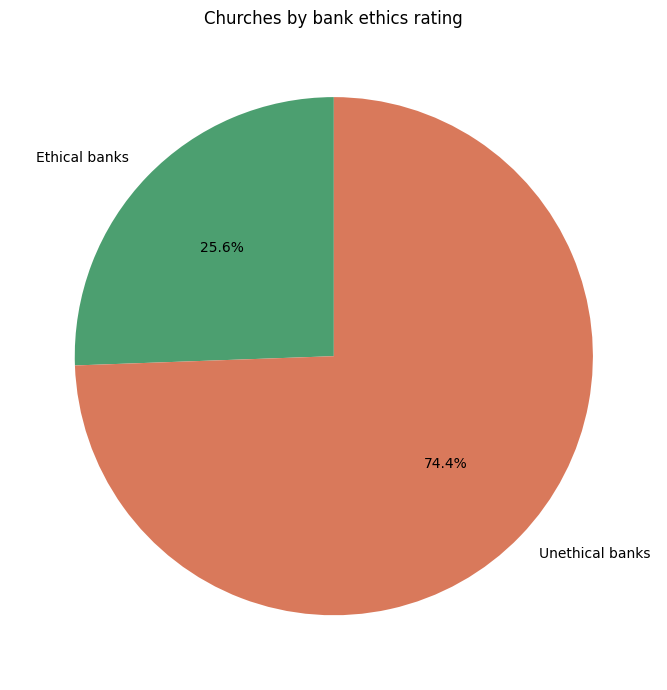

In [6]:
ethical_mask = results["rating"] > 3
ethical_counts = pd.Series(
    {
        "Ethical banks": int(ethical_mask.sum()),
        "Unethical banks": int((~ethical_mask).sum()),
    }
)

fig, ax = plt.subplots(figsize=(7, 7))
ethical_counts.plot.pie(
    ax=ax,
    autopct="%1.1f%%",
    startangle=90,
    colors=["#4c9f70", "#d9795b"],
    ylabel="",
)
ax.set_title("Churches by bank ethics rating")
plt.tight_layout()
plt.show()


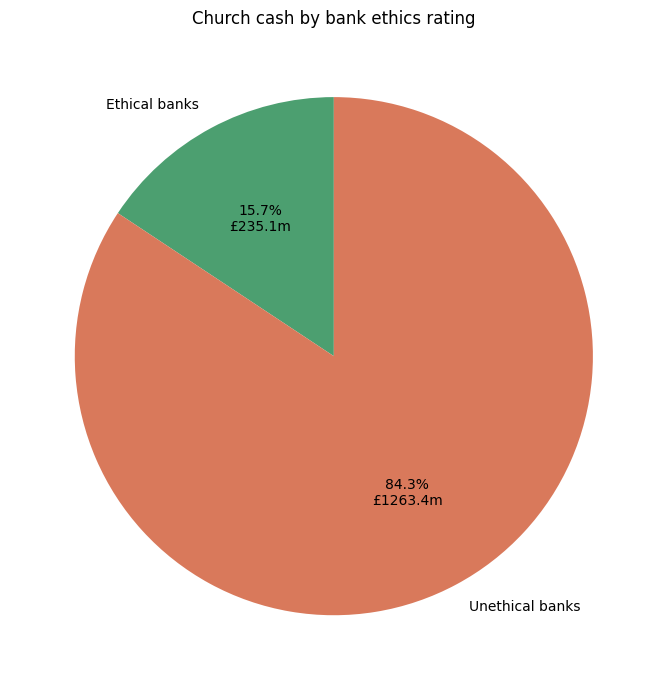

In [7]:
cash_by_ethics = pd.Series(
    {
        "Ethical banks": results.loc[ethical_mask, "cash"].sum(),
        "Unethical banks": results.loc[~ethical_mask, "cash"].sum(),
    }
)

fig, ax = plt.subplots(figsize=(7, 7))
cash_by_ethics.plot.pie(
    ax=ax,
    autopct=lambda percent: f"{percent:.1f}%\n£{percent * cash_by_ethics.sum() / 100 / 1e6:.1f}m",
    startangle=90,
    colors=["#4c9f70", "#d9795b"],
    ylabel="",
)
ax.set_title("Church cash by bank ethics rating")
plt.tight_layout()
plt.show()


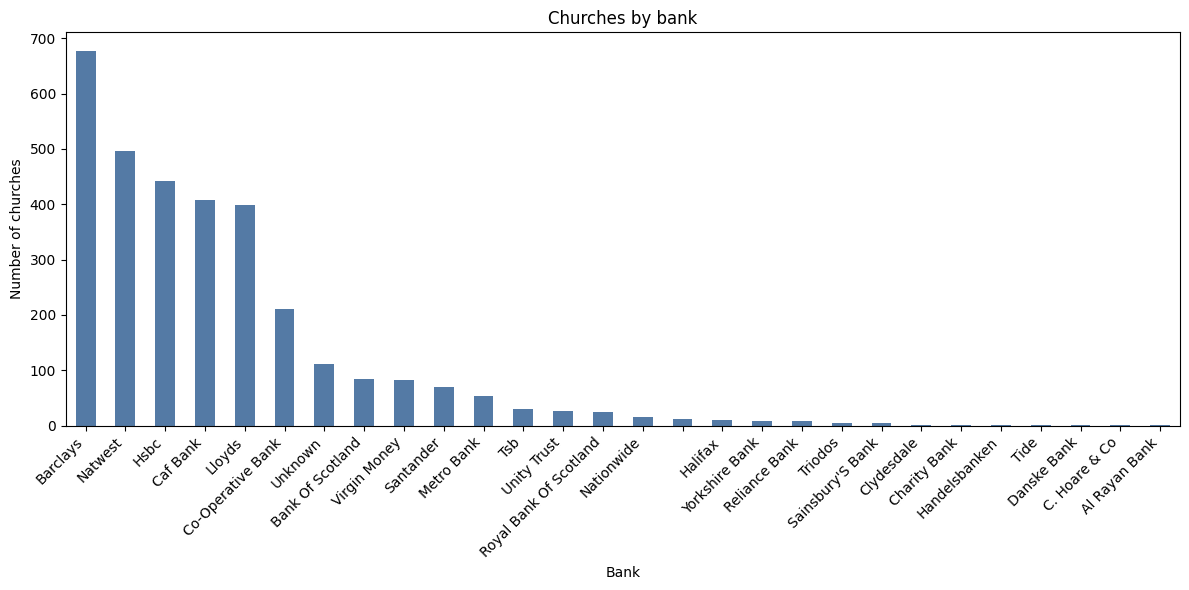

In [8]:
churches_by_bank = results["principal_bank"].value_counts().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(12, 6))
churches_by_bank.plot.bar(ax=ax, color="#547aa5")
ax.set_title("Churches by bank")
ax.set_xlabel("Bank")
ax.set_ylabel("Number of churches")
ax.tick_params(axis="x", labelrotation=45)
plt.setp(ax.get_xticklabels(), ha="right")
plt.tight_layout()
plt.show()


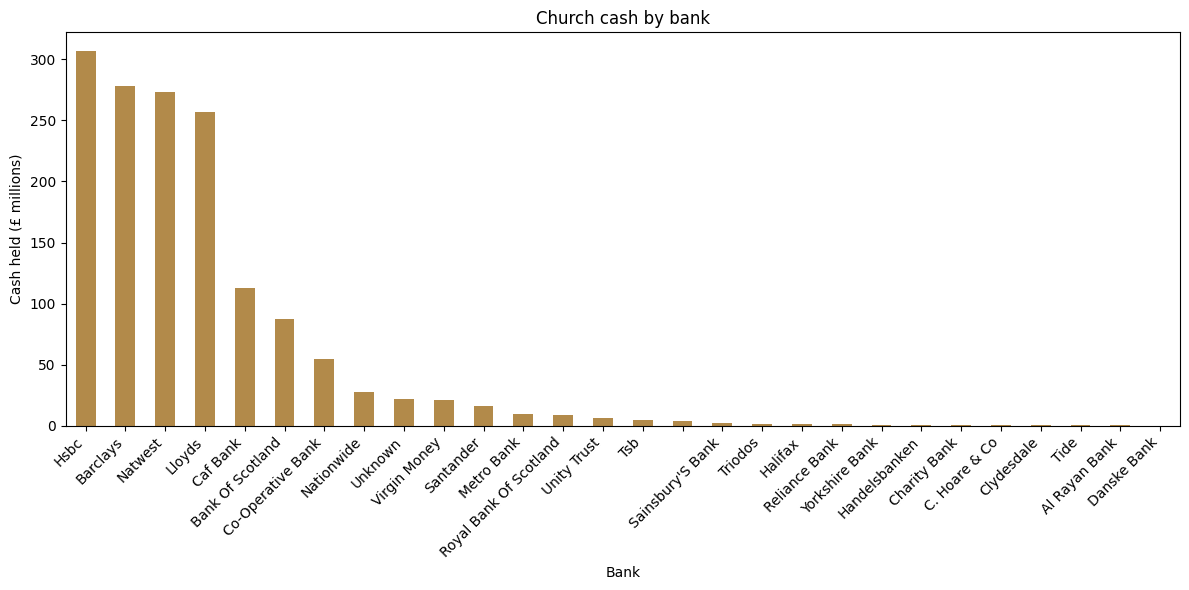

In [9]:
cash_by_bank = (
    results.groupby("principal_bank")["cash"].sum().sort_values(ascending=False) / 1e6
)

fig, ax = plt.subplots(figsize=(12, 6))
cash_by_bank.plot.bar(ax=ax, color="#b28a4a")
ax.set_title("Church cash by bank")
ax.set_xlabel("Bank")
ax.set_ylabel("Cash held (£ millions)")
ax.tick_params(axis="x", labelrotation=45)
plt.setp(ax.get_xticklabels(), ha="right")
plt.tight_layout()
plt.show()
